# Datasets Analysis

This is a preliminary datasets analysis to observe certain detail about the datasets.

In [76]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import warnings
import kagglehub
import matplotlib.dates as mdates
import re
warnings.filterwarnings("ignore")

## Analysis of "Because of..." Dataset

In [77]:
data_path = kagglehub.dataset_download("hossaingh/because-of")
df = pd.read_csv(os.path.join(data_path, "Because_of_14-30Sept.csv"), low_memory=False)
df.head()

,text,display_name,Timestamp,retweet_count,favorite_count,reply_count,quote_count,media_1,media_2,media_3,media_4
0,برای هر باری که آرزو کردیم ایران به دنیا نمیوم...,marcellasne,Sat Sep 24 01:15:20 +0000 2022,0,0,0,0,NaN,NaN,NaN,NaN
1,برای پسرایی که اجباری میرن سربازی و بهشون تجاو...,مُلحدِ زلال پرست,Fri Sep 23 20:49:43 +0000 2022,13,13,0,0,NaN,NaN,NaN,NaN
2,برای خیلی از عزیزانی که ،عمرشان تلف شد و،از مس...,G. shakeri,Fri Sep 23 22:16:26 +0000 2022,4,6,0,0,NaN,NaN,NaN,NaN
3,برای مهسا ،برای ایران،#مهسا_امینی،#Mahsa_Amini...,گابلر,Fri Sep 23 20:44:06 +0000 2022,0,0,0,0,NaN,NaN,NaN,NaN
4,برای همه اون جوون های بهایی،مسیحی،زرتشت... که ...,Violet Djawadi,Sun Sep 25 21:39:56 +0000 2022,0,0,0,0,NaN,NaN,NaN,NaN


# Total Rows & Null Columns

In [78]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 971947 entries, 0 to 971946
Data columns (total 11 columns):
 #   Column          Non-Null Count   Dtype 
---  ------          --------------   ----- 
 0   text            971947 non-null  object
 1   display_name    971909 non-null  object
 2   Timestamp       971947 non-null  object
 3   retweet_count   971947 non-null  int64 
 4   favorite_count  971947 non-null  int64 
 5   reply_count     971947 non-null  int64 
 6   quote_count     971947 non-null  int64 
 7   media_1         45613 non-null   object
 8   media_2         2067 non-null    object
 9   media_3         762 non-null     object
 10  media_4         461 non-null     object
dtypes: int64(4), object(7)
memory usage: 81.6+ MB


# Describe

In [79]:
df.describe(include='all')

,text,display_name,Timestamp,retweet_count,favorite_count,reply_count,quote_count,media_1,media_2,media_3,media_4
count,971947,971909,971947,971947.000000,971947.000000,971947.000000,971947.00000,45613,2067,762,461
unique,907441,142352,407026,NaN,NaN,NaN,NaN,45461,2060,760,459
top,برای #مهسا_امینی,Iran opt,Sat Sep 24 09:37:05 +0000 2022,NaN,NaN,NaN,NaN,https://pbs.twimg.com/ext_tw_video_thumb/15748...,https://pbs.twimg.com/media/FdV3WFaWAAA-z31.jpg,https://pbs.twimg.com/media/FdV3W9xXEAQS16s.jpg,https://pbs.twimg.com/media/FdV3XcdXgAEuhzy.jpg
freq,2377,2697,19,NaN,NaN,NaN,NaN,20,2,2,2
mean,NaN,NaN,NaN,15.292311,28.800155,1.878161,0.23164,NaN,NaN,NaN,NaN
std,NaN,NaN,NaN,397.355022,853.489656,64.750463,8.06796,NaN,NaN,NaN,NaN
min,NaN,NaN,NaN,0.000000,0.000000,0.000000,0.00000,NaN,NaN,NaN,NaN
25%,NaN,NaN,NaN,0.000000,0.000000,0.000000,0.00000,NaN,NaN,NaN,NaN
50%,NaN,NaN,NaN,0.000000,1.000000,0.000000,0.00000,NaN,NaN,NaN,NaN
75%,NaN,NaN,NaN,2.000000,5.000000,0.000000,0.00000,NaN,NaN,NaN,NaN


# Amount of NaN - Per Columns

In [80]:
df.isna().sum()

text                   0
display_name          38
Timestamp              0
retweet_count          0
favorite_count         0
reply_count            0
quote_count            0
media_1           926334
media_2           969880
media_3           971185
media_4           971486
dtype: int64

# Memory & Shape

In [81]:
memory_mb = df.memory_usage().sum() / (1024 * 1024)
print(f"The dataframe uses {memory_mb:.2f} MB of memory")

The dataframe uses 81.57 MB of memory


In [82]:
print(f"The dataset shape is (data rows, features): {df.shape}")

The dataset shape is (data rows, features): (971947, 11)


# Duplicate Text

In [83]:
# how many text are duplicate
dups = df["text"].duplicated().sum()
# how many entire rows are duplicate
dups_rows = df.duplicated().sum()

print(f"Amount of texts duplicated: {dups}\nAmount of full duplicated rows: {dups_rows}")


Amount of texts duplicated: 64506
Amount of full duplicated rows: 72


# Unique Data

In [84]:
df.nunique()

text              907441
display_name      142352
Timestamp         407026
retweet_count       2150
favorite_count      2708
reply_count         1019
quote_count          358
media_1            45461
media_2             2060
media_3              760
media_4              459
dtype: int64

# Frequency of Length of Text

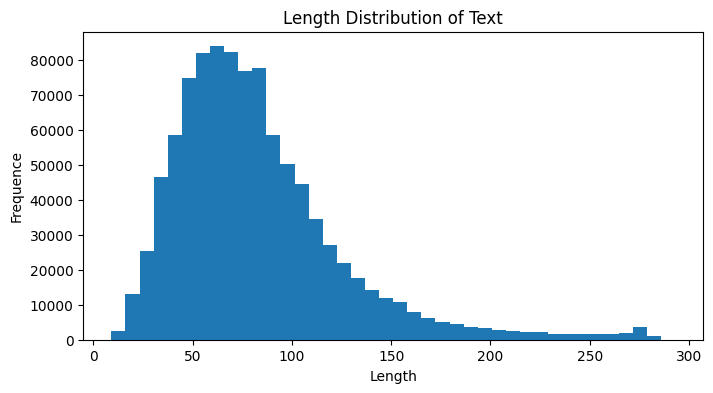

In [85]:
df["len"] = df["text"].astype(str).apply(len)

plt.figure(figsize=(8,4))
plt.hist(df["len"], bins=40)
plt.title("Length Distribution of Text")
plt.xlabel("Length")
plt.ylabel("Frequence")
plt.show()

# Clean Data Analysis

In [86]:
def hashtag(txt):
    return '#' in str(txt)

emojis = re.compile("["
         u"\U0001F600-\U0001F64F"
         u"\U0001F300-\U0001F5FF"
         u"\U0001F680-\U0001F6FF"
         u"\U0001F1E0-\U0001F1FF"
         "]+", flags=re.UNICODE)

def emoji(txt):
    return bool(emojis.search(str(txt)))

def tag(txt):
    return bool(re.search(r'@\w+', str(txt)))

def url(txt):
    return bool(re.search(r'http\S+|www\S+', str(txt)))

df['hashtag'] = df['text'].apply(hashtag)
df['emoji'] = df['text'].apply(emoji)
df['tag'] = df['text'].apply(tag)
df['url'] = df['text'].apply(url)

print(
    f"Text w url: {df["url"].sum()}\nText w @: {df["tag"].sum()}\nText w #: {df["hashtag"].sum()}\nText w emojis: {df["emoji"].sum()}\n"
    )

Text w url: 160
Text w @: 5192
Text w #: 971725
Text w emojis: 36908



# Time Period Analysis

In [87]:
# drop NaN values cause if not looks awful haha, only for plotting
# df = df.dropna()
# df.reset_index(inplace=True, drop=True)
# df.shape

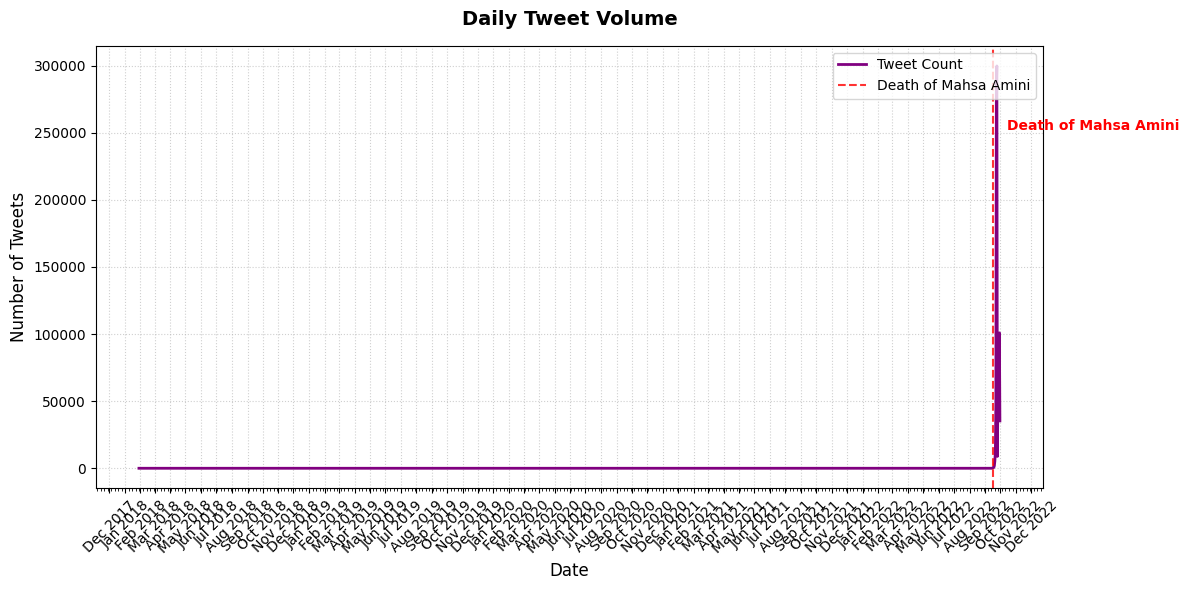

In [88]:
df['Timestamp'] = pd.to_datetime(df['Timestamp'], format='mixed')

tweets_per_day = df.resample('D', on='Timestamp').size()

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(tweets_per_day.index, tweets_per_day.values, color='purple', linewidth=2, label='Tweet Count')

event_date = pd.Timestamp('2022-09-16') # death of Mahsa Amini
ax.axvline(event_date, color='red', linestyle='--', alpha=0.8, label='Death of Mahsa Amini')

ax.annotate('Death of Mahsa Amini', 
            xy=(event_date, ax.get_ylim()[1]*0.8),
            xytext=(10, 0), textcoords='offset points', 
            color='red', fontsize=10, fontweight='bold')

ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax.xaxis.set_minor_locator(mdates.WeekdayLocator())

ax.set_title('Daily Tweet Volume', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Date', fontsize=12)
ax.set_ylabel('Number of Tweets', fontsize=12)
ax.grid(True, linestyle=':', alpha=0.6)
ax.legend(loc='upper right')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()